<a href="https://colab.research.google.com/github/JantikarShobith/BIS_LAB/blob/main/1BM24CS351_Week3_AntColonyOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Ant Colony Optimization for Delivery Routes...

Iteration   1 | Best Delivery Route Distance: 363.28 km
Iteration  20 | Best Delivery Route Distance: 312.48 km
Iteration  40 | Best Delivery Route Distance: 312.48 km
Iteration  60 | Best Delivery Route Distance: 312.48 km
Iteration  80 | Best Delivery Route Distance: 312.48 km
Iteration 100 | Best Delivery Route Distance: 312.48 km

        DELIVERY ROUTE OPTIMIZATION RESULTS     
 Total Route Distance : 312.48 km
 Stop Order Sequence:
WAREHOUSE -> Drop 10 -> Drop 12 -> Drop 8 -> Drop 3 -> Drop 15 -> Drop 11 -> Drop 7 -> Drop 2 -> Drop 5 -> Drop 13 -> Drop 1 -> Drop 6 -> Drop 4 -> Drop 14 -> Drop 9 -> WAREHOUSE


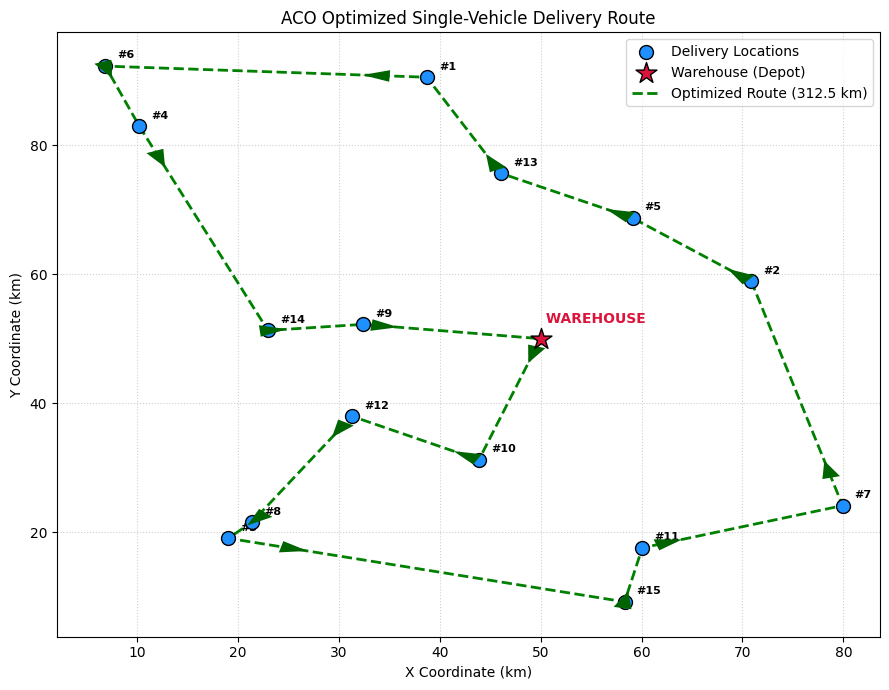

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

NUM_DELIVERIES = 15
MAP_SIZE = 100.0

# Warehouse location (Depot)
WAREHOUSE = np.array([50.0, 50.0])

# Generate random delivery customer locations around warehouse
CUSTOMERS = np.random.uniform(5.0, MAP_SIZE - 5.0, size=(NUM_DELIVERIES, 2))

# Full location array: Node 0 = Warehouse, Nodes 1..N = Deliveries
LOCATIONS = np.vstack([WAREHOUSE, CUSTOMERS])
NUM_NODES = len(LOCATIONS)

# Precompute Distance Matrix D (Euclidean)
diff = LOCATIONS[:, np.newaxis, :] - LOCATIONS[np.newaxis, :, :]
DIST_MATRIX = np.sqrt(np.sum(diff**2, axis=-1))

# Avoid division by zero on self-loops
np.fill_diagonal(DIST_MATRIX, 1e-10)


NUM_ANTS = 25
MAX_ITER = 100
ALPHA = 1.0       # Pheromone importance factor
BETA = 3.0        # Heuristic visibility factor (distance)
EVAPORATION_RATE = 0.1  # Pheromone decay rate (rho)
Q = 100.0         # Pheromone deposit multiplier

# Initial Pheromone Level
PHEROMONE = np.ones((NUM_NODES, NUM_NODES)) * 1e-3
HEURISTIC = 1.0 / DIST_MATRIX

def construct_ant_tour(pheromone_matrix):
    """Generates a route starting and ending at the warehouse (Node 0)."""
    tour = [0]  # Start at warehouse
    unvisited = set(range(1, NUM_NODES))

    current_node = 0
    while unvisited:
        unvisited_list = list(unvisited)

        # Calculate transition probabilities for unvisited nodes
        tau = pheromone_matrix[current_node, unvisited_list] ** ALPHA
        eta = HEURISTIC[current_node, unvisited_list] ** BETA
        probabilities = tau * eta

        prob_sum = np.sum(probabilities)
        if prob_sum == 0:
            probs = np.ones(len(unvisited_list)) / len(unvisited_list)
        else:
            probs = probabilities / prob_sum

        # Select next location via roulette wheel choice
        next_node = np.random.choice(unvisited_list, p=probs)
        tour.append(next_node)
        unvisited.remove(next_node)
        current_node = next_node

    # Return to warehouse
    tour.append(0)
    return tour

def calculate_tour_distance(tour):
    """Calculates total distance traveled for a complete tour vector."""
    distance = 0.0
    for i in range(len(tour) - 1):
        distance += DIST_MATRIX[tour[i], tour[i+1]]
    return distance

def run_ant_colony_optimization():
    global PHEROMONE

    gbest_tour = None
    gbest_distance = float('inf')

    print("Starting Ant Colony Optimization for Delivery Routes...\n")

    for iteration in range(MAX_ITER):
        all_tours = []
        all_distances = []

        # Step 1: All ants construct delivery tours
        for ant in range(NUM_ANTS):
            tour = construct_ant_tour(PHEROMONE)
            dist = calculate_tour_distance(tour)
            all_tours.append(tour)
            all_distances.append(dist)

            # Track global best route
            if dist < gbest_distance:
                gbest_distance = dist
                gbest_tour = tour

        # Step 2: Pheromone Evaporation
        PHEROMONE *= (1.0 - EVAPORATION_RATE)

        # Step 3: Pheromone Deposit
        for tour, dist in zip(all_tours, all_distances):
            deposit = Q / dist
            for i in range(len(tour) - 1):
                u, v = tour[i], tour[i+1]
                PHEROMONE[u, v] += deposit
                PHEROMONE[v, u] += deposit  # Symmetric update

        # Periodic output log
        if (iteration + 1) % 20 == 0 or iteration == 0:
            print(f"Iteration {iteration+1:3d} | Best Delivery Route Distance: {gbest_distance:.2f} km")

    return gbest_tour, gbest_distance


best_route, min_distance = run_ant_colony_optimization()

print("\n=================================================")
print("        DELIVERY ROUTE OPTIMIZATION RESULTS     ")
print("=================================================")
print(f" Total Route Distance : {min_distance:.2f} km")
print(" Stop Order Sequence:")

route_names = []
for idx in best_route:
    if idx == 0:
        route_names.append("WAREHOUSE")
    else:
        route_names.append(f"Drop {idx}")
print(" -> ".join(route_names))
print("=================================================")

# Plotting the Final Delivery Route
plt.figure(figsize=(9, 7))

# Draw non-warehouse delivery targets
plt.scatter(CUSTOMERS[:, 0], CUSTOMERS[:, 1], color='dodgerblue', s=100,
            edgecolors='black', label='Delivery Locations', zorder=4)

# Draw Warehouse
plt.scatter(WAREHOUSE[0], WAREHOUSE[1], color='crimson', s=250, marker='*',
            edgecolors='black', label='Warehouse (Depot)', zorder=5)

# Label stops
plt.text(WAREHOUSE[0], WAREHOUSE[1] + 2.5, " WAREHOUSE", fontsize=10, weight='bold', color='crimson')
for i, pt in enumerate(CUSTOMERS, 1):
    plt.text(pt[0] + 1.2, pt[1] + 1.2, f"#{i}", fontsize=8, color='black', weight='bold')

# Draw optimized route line segments
route_coords = LOCATIONS[best_route]
plt.plot(route_coords[:, 0], route_coords[:, 1], 'g--', linewidth=2.0,
         label=f'Optimized Route ({min_distance:.1f} km)', zorder=3)

# Arrow heads to indicate direction of travel
for i in range(len(route_coords) - 1):
    p1 = route_coords[i]
    p2 = route_coords[i+1]
    dx, dy = (p2[0] - p1[0]) * 0.2, (p2[1] - p1[1]) * 0.2
    plt.arrow(p1[0], p1[1], dx, dy, shape='full', lw=0, length_includes_head=True,
              head_width=1.8, color='darkgreen', zorder=4)

plt.title("ACO Optimized Single-Vehicle Delivery Route", fontsize=12)
plt.xlabel("X Coordinate (km)")
plt.ylabel("Y Coordinate (km)")
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()